# PHYS3116 Tutorial 5: Functions, the IMF and Distance Measures

In [2]:
import random

import astropy.cosmology.units as cu
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM
from scipy.optimize import curve_fit

We will start with an introduction to dictionaries

In [3]:
student = {
    "name": "Alice",
    "age": 20,
    "grade": "HD"
}

In [4]:
student = {
    "name": "Alice",
    "age": 20
}

print(student["name"])

Alice


In [5]:
print(student.get("age"))

20


In [6]:
student["major"] = "Physics"

print(student)

{'name': 'Alice', 'age': 20, 'major': 'Physics'}


In [7]:
student["age"] = 21

print(student)

{'name': 'Alice', 'age': 21, 'major': 'Physics'}


In [8]:
for key, value in student.items():
    print(key, value)

name Alice
age 21
major Physics


In [9]:
student = {
    "name": "Alice",
    "age": 20,
    "major": "Physics"
}

print(student.keys())

dict_keys(['name', 'age', 'major'])


In [10]:
d = {}

d["a"] = 1          # add
d["a"] = 2          # update
print(d["a"])       # access
print(d.keys())     # all keys
print(d.values())   # all values

for key in d.keys():
    print(key)

print()

for key, value in d.items():
    print(key, value)

2
dict_keys(['a'])
dict_values([2])
a

a 2


## Activity:

Simulate a population of stellar streams and estimate how many stars have been detected in each.

In [11]:
streams = {
    "Sagittarius": 0,
    "GSE": 0,
    "Sequoia": 0,
    "Thamnos": 0,
    "Helmi": 0,
    "Jhelum": 0
}

Assign a number of stars to each stream by looping. Hint: use random.randint(10, 500)

In [12]:
for key in streams.keys():
    streams[key] = random.randint(10,500)
streams

{'Sagittarius': 301,
 'GSE': 186,
 'Sequoia': 262,
 'Thamnos': 222,
 'Helmi': 251,
 'Jhelum': 18}

Find and print the stream with the most amount of stars

In [13]:
largest_num = max(streams.values())
mask = np.array(list(streams.values())) == largest_num
largest_stream = np.array(list(streams.keys()))[mask][0]
print(largest_stream,largest_num)

Sagittarius 301


# Astropy

Let's introduce a new Python package, Astropy. As hinted by the name, this package is designed to be used by astronomers. 

In [14]:
# A really useful tool is being able to define units
distance = 30 * u.Mpc
distance

<Quantity 30. Mpc>

In [15]:
time = 20 * u.s
time

<Quantity 20. s>

In [16]:
# Define cosmology
# lets use some approximate values for now.

H0 = 70 # Hubble constant
Om0 = 0.3 # Present day matter desnity


cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)
print(cosmo)

FlatLambdaCDM(H0=70.0 km / (Mpc s), Om0=0.3, Tcmb0=0.0 K, Neff=3.04, m_nu=None, Ob0=None)


In [17]:
# we can use this cosmology to get particular properties at a specified redshift
z = 0 * cu.redshift
cosmo.age(z)

<Quantity 13.46698395 Gyr>

In [18]:
# what is the look back time at this redshift?

cosmo.age(0) - cosmo.age(z)

<Quantity 0. Gyr>

In [19]:
# Can also do for an array of redshifts

cosmo.age([0.5, 1, 1.5] * cu.redshift)

<Quantity [8.42634602, 5.75164694, 4.20073193] Gyr>

In [20]:
# we can also find distances
cosmo.comoving_distance(0)

<Quantity 0. Mpc>

In [21]:
# How far away is the object in today's Universe?
cosmo.comoving_distance(z)

<Quantity 0. Mpc>

In [22]:
# How far away was the galaxy when it emitted the light we see today (assuming the galaxy follows the Hubble flow)?
cosmo.comoving_distance(z)/(1+z)

<Quantity 0. Mpc>

# Exercises

## 1) Plotting Distances
#### a) Imagine you have 10 spectra containing the $H\alpha$ line. Across these spectra you find that the $H\alpha$ line varies between 7,000 and 12,000 Angstroms. Recall that at z = 0,  $\lambda_{H\alpha, rest}$ = 6,563 Angstroms. Pretend that the 10 $H\alpha$ lines are evenly spaced between 7,000 and 12,000 Angstroms. Make a plot of $\lambda_{H\alpha, obs}$ - $\lambda_{H\alpha, rest}$ vs Distance to the object emmitting the spectra. You must use functions to do this where one of the inputs is the array of $\lambda_{H\alpha}$ wavelengths and the output is the distances.

#### b) Using the fitting_func and scipy.curve_fit, fit a curve to the data. For simplicity we will assume a quadratic fit at this redshift range

#### c) Pretend that the telescope can only resolve wavelengths up to (and including) 8,000 Angstroms. What is the largest lookback time that we can observe the $H\alpha$ line.

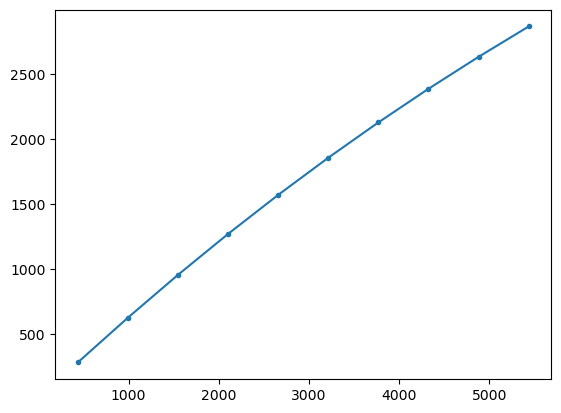

In [62]:
# 1a)

# --- Define cosmology ---
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
lambda_obs_array = np.linspace(7000,12000,10)

def LambdaArray2Dist(lambda_obs_array):
    lambda_rest = 6563
    delta_lambda = lambda_obs_array-lambda_rest
    z = delta_lambda / lambda_rest
    dist = cosmo.comoving_distance(z)
    return dist,z

dist,z = LambdaArray2Dist(lambda_obs_array)

plt.plot(delta_lambda,dist,marker=".")


Quadratic fit parameters
a = -2.2607 +- 1.99890
b = 0.64893 +- 0.00120
c = 3.00226 +- 1.53579


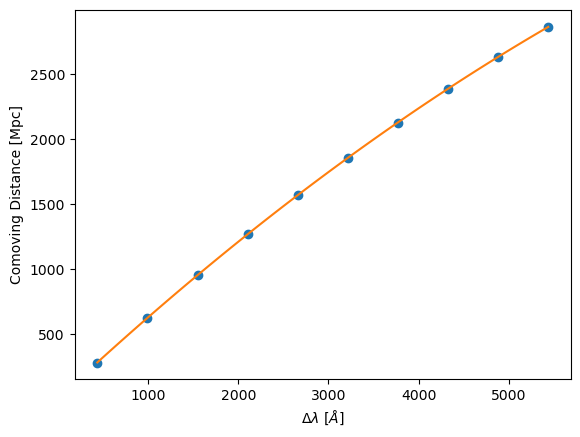

In [63]:
# 1b)
# popt returns values of a, b used in the fitting_func. pcov is the covariance (error) matrix on the a, b values
# plot the data and best fit

def quad(x,a,b,c):
    return a*x**2 + b*x +c

popt, pcov = curve_fit(quad,delta_lambda,dist)    # - Calls scipy.curve_fit, gets optimised parameters and their covariance matrix
perr = np.sqrt(np.diag(pcov))

xfit = np.linspace(min(delta_lambda),max(delta_lambda),100)
yfit = quad(xfit,*popt)

plt.plot(delta_lambda,dist,marker="o",linewidth=0)
plt.plot(xfit,yfit)
plt.xlabel(r"$\Delta \lambda$ [$\AA$]")
plt.ylabel(r"Comoving Distance [Mpc]")

print("Quadratic fit parameters")
Params = quad.__code__.co_varnames
for i in range(len(popt)):
    print("%s = %.7s +- %.7s"%(Params[i+1],popt[i],perr[i]))

In [65]:
# 1c)
dist,z = LambdaArray2Dist(8000)
print("Max Lookback Time:")
cosmo.lookback_time(z)


Max Lookback Time:


<Quantity 2.62930846 Gyr>

# Exercises

## 1) Plotting the Salpeter IMF
#### a) Again using functions, plot the salpeter IMF as a function of mass. Reminder that Function $\propto m^{-2.35}$ for range (0.1Msol - 100Msol). Plot the curve.
#### b) Calculate the fraction of the total stellar mass in our galaxy being formed at any one time that is contained in: Stars with mass between 0.1Msol and 0.3Msol (hint: total_mass = np.trapz(m * xi, m))

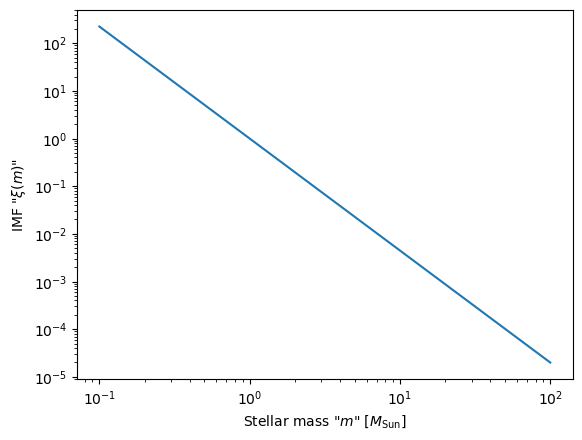

In [88]:
# 2a)

def salpeter_imf(m, alpha=2.35):
    """
    Salpeter IMF: xi(m) ∝ m^(-alpha)
    m : stellar mass [Msun]
    alpha : slope
    Returns xi(m)
    """
    return m**(-alpha)

# plot the curve. Log both axes.

m = np.logspace(-1, 2, 1000)
xi = salpeter_imf(m)

plt.plot(m,xi)
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r'Stellar mass "$m$" [$M_{\text{Sun}}$]')
plt.ylabel(r'IMF "$\xi(m)$"');

In [114]:
# --- Mass fraction function using np.trapz ---
def mass_fraction(m, m_min, m_max, alpha=2.35):
    """
    Fraction of total stellar mass in [m_min, m_max] using trapezoidal integration.
    """

    InRange = (m_min<=m) & (m<=m_max)

    xi = salpeter_imf(m, alpha=2.35)

    total_mass = np.trapz(m * xi, m)
    inrange_mass = np.trapz(m[InRange] * xi[InRange], m[InRange])
    
    frac=inrange_mass/total_mass

    return frac

In [126]:
mass_fraction(m, 0.10, 0.3)

0.3488570110301268